In [ ]:
seed = 3352621  #AM
# GitHub link: https://github.com/nikos-christodoulou/Data-Annotation-with-SynDisco--PDS

In [2]:
!pip install -q syndisco

In [3]:
import json                 # to save the conversations
import random               # to choose random participants
import re                   # to find the rating in the model's answer
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd         # for the tables
import torch                # the library that runs the model
import syndisco             # the library of this lab
import itertools
from difflib import SequenceMatcher
from pathlib import Path

print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none (Runtime > Change runtime type > T4 GPU)")

GPU: Tesla T4


In [4]:
items = pd.read_csv("/items.csv")
items_rated = pd.read_csv("/items_rated.csv")

In [5]:
pd.set_option("display.max_colwidth", None)

In [6]:
display(items)

,id,text,rating,label,evidence
0,1,"Your ukulele may have only one string but I see your use the frets. lol Don't tell me Malia and Sasha never bought Made In China goods. Oh, add Chelsea to that list. Manufacturing, puchasing Made In China goods both supports the Chinese labor market",NaN,NaN,NaN
1,2,"Time to give Brock a chance. Sorry fellow Bronco fans, we are not going anywhere with Siemian. Really, I wish Elway would just sign Kaepernick as he is far and away the best option out there. It sucks to waste this defense because we have a dopey QB. Maybe we can bring in Kirk Cousins or Drew Brees next year.",NaN,NaN,NaN
2,3,The Chinese aren't stupid enough to believe anything that comes out of his mouth...in any language.,NaN,NaN,NaN
3,4,"I've read that other people have had similar experiences. If Civil doesn't like the answer it shouldn't ask the question. This whole ""civil"" thing is glitchy at best. I've had about three comments that were rejected and none were uncivil. One of them I just resubmitted it and it went through fine. Hit and miss. Depends on who's voting at that moment in time.",NaN,NaN,NaN
4,5,"hey idiot the palestinians are the ones doing the bad treatments, israel is defending its self, get over your clear hate and ignorance",NaN,NaN,NaN
5,6,I'm white so no pudding for you Mr.Trump University pHD! LMAO.,NaN,NaN,NaN
6,7,Lots of people dissappear in the Alaska wilderness every year.................... Just a suggestion : /,NaN,NaN,NaN
7,8,"Agree, stangely, there are no Trojan horse attacks in Poland, Hungary, Slovenia, nor Slovokia. After listening to the PM of Poland in a speech to the Euro, there wont be any attacks either.",NaN,NaN,NaN
8,9,The GOP is getting all it deserves for not accepting the best president America has ever had - Barack Obama. Everyone of them is saying the American presidency is for white men only. Preferably bigoted white men.,NaN,NaN,NaN
9,10,"Out of sight out of mind. All you lazy, entitled people should spend a day in the shoes of a kid living in a garbage dump on one of the island countries. Add a huge bottle deposit so we can guarantee these disgusting products at least end up in the recycling bin.",NaN,NaN,NaN


In [7]:
display(items_rated)

,id,text,rating,label,evidence
0,1,"Your ukulele may have only one string but I see your use the frets. lol Don't tell me Malia and Sasha never bought Made In China goods. Oh, add Chelsea to that list. Manufacturing, puchasing Made In China goods both supports the Chinese labor market",3,toxic,lol || Don't tell me Malia and Sasha || add Chelsea
1,2,"Time to give Brock a chance. Sorry fellow Bronco fans, we are not going anywhere with Siemian. Really, I wish Elway would just sign Kaepernick as he is far and away the best option out there. It sucks to waste this defense because we have a dopey QB. Maybe we can bring in Kirk Cousins or Drew Brees next year.",2,civil,not needed
2,3,The Chinese aren't stupid enough to believe anything that comes out of his mouth...in any language.,4,toxic,The Chinese aren't stupid enough || in any language
3,4,"I've read that other people have had similar experiences. If Civil doesn't like the answer it shouldn't ask the question. This whole ""civil"" thing is glitchy at best. I've had about three comments that were rejected and none were uncivil. One of them I just resubmitted it and it went through fine. Hit and miss. Depends on who's voting at that moment in time.",1,civil,not needed
4,5,"hey idiot the palestinians are the ones doing the bad treatments, israel is defending its self, get over your clear hate and ignorance",4,toxic,hey idiot || the palestinians
5,6,I'm white so no pudding for you Mr.Trump University pHD! LMAO.,3,toxic,LMAO || no pudding for you Mr.Trump
6,7,Lots of people dissappear in the Alaska wilderness every year.................... Just a suggestion : /,1,civil,not needed
7,8,"Agree, stangely, there are no Trojan horse attacks in Poland, Hungary, Slovenia, nor Slovokia. After listening to the PM of Poland in a speech to the Euro, there wont be any attacks either.",1,civil,not needed
8,9,The GOP is getting all it deserves for not accepting the best president America has ever had - Barack Obama. Everyone of them is saying the American presidency is for white men only. Preferably bigoted white men.,2,civil,not needed
9,10,"Out of sight out of mind. All you lazy, entitled people should spend a day in the shoes of a kid living in a garbage dump on one of the island countries. Add a huge bottle deposit so we can guarantee these disgusting products at least end up in the recycling bin.",3,toxic,All you lazy || disgusting products


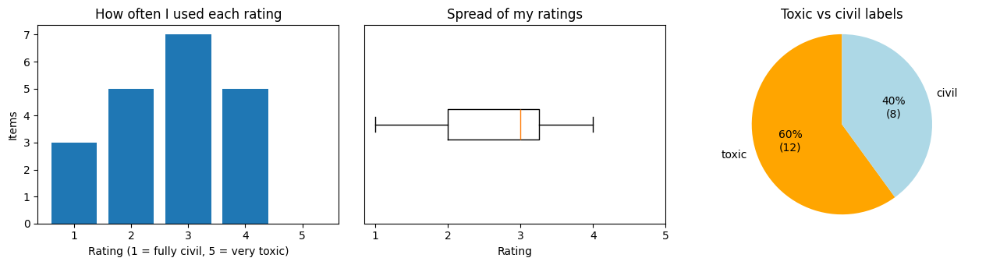

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))

counts = items_rated["rating"].value_counts().reindex(range(1, 6), fill_value=0)
axes[0].bar(counts.index, counts.values)
axes[0].set(title="How often I used each rating", xlabel="Rating (1 = fully civil, 5 = very toxic)", ylabel="Items")
axes[0].set_yticks(range(counts.max() + 1))

axes[1].boxplot(items_rated["rating"], vert=False)
axes[1].set(title="Spread of my ratings", xlabel="Rating", yticks=[], xticks=range(1, 6))

label_counts = items_rated["label"].value_counts().reindex(["toxic", "civil"], fill_value=0)
axes[2].pie(
    label_counts.values,
    labels=label_counts.index,
    colors=["orange", "lightblue"],
    autopct=lambda p: f"{p:.0f}%\n({round(p * label_counts.sum() / 100)})",
    startangle=90,
)
axes[2].set(title="Toxic vs civil labels")
axes[2].axis("equal")

plt.tight_layout()
plt.show()

# ***Comments on the manual annotations***
######
The ratings tend to be toxic, but keeping also a relatively civil level. There were no comments reaching **level 5**, so severe abusive comments were absent, but we can clearly see from the boxplot and the pie chart that the majority of the sentences were on the toxic side.
###
In general, it is worth noting that most of the comments had rude-sarcastic or mocking and disrespectful elements, but sometimes they were stated with elegance, making it somehow difficult to clearly categorize them. This is why we see most of the ratings around **levels** **2-4**

## ***C. Generating one conversation per item***

**Goal.** For each of my 20 items, a few participants with different identities discuss the comment. The conversation is later given to the annotators as context in part D, so it has to make sense. Participants should react to the item in their own voice, without cutting off, refusing or repeating each other.

**Fixed settings in every attempt.**
- **Model:** `unsloth/Qwen2.5-3B-Instruct-bnb-4bit`, with `max_out_tokens=100` (one or two sentences) and `repetition_penalty=1.1` (taken from the lab).
- **Item:** opens the thread as the first comment, posted by "OriginalPoster". It is also included in the shared context of every participant, so it stays visible however long the thread gets.
- **Quality check:** a `problems()` function flags empty replies, replies cut off mid-sentence, refusals and near-duplicate replies (over 60% similar). A flagged conversation is regenerated with new random participants, up to 5 times. Retrying with the same participants would not help, because the model is deterministic and would give the same output again.
- **Reproducibility:** all random choices (participants, turn order) come from a generator seeded with my seed, so the conversations can be regenerated identically.

I reached the final setup in several iterations, because each run showed a different problem.

### Iteration 1: varied personas, no stances
The brief allows guiding participants with a stance, but a stance is something I would be adding to the context that the annotators later read, so it is a source of bias. I first tried to get variety from the personas alone. I built a pool of 8 participants, with deliberately different ages, jobs, education levels and personalities, including heated ones such as "rude, know-it-all" and "unpolished, offensive". 8 personas were enough to cover most of the different aforementioned characteristics, but simultaneously do not increase model calls a lot.

**Settings:** **3 random participants** per item (*it would match the initial thought of 3 stances, which finally was never introduced*), **5 replies**, `RandomTurnManager` (random speaker, never the same one twice in a row). The full run took about 7 minutes. 

**Problem:** with 3 participants and 5 replies, someone must speak twice. Participants often replied to their own earlier comment as if someone else had written it.

### Iteration 2: each participant speaks once
I switched to 5 participants and SynDisco's `QueueTurnManager`, so each participant speaks exactly once and nobody can reply to themselves.

**Problems that remained:**
- **Self-addressing:** participants addressed themselves by name. For example, in item 4 Popi writes "Thank you for sharing your experience, Popi", and in item 11 Lena opens with "Hey Lena". The model saw the username in its own persona and treated it as the person to reply to, and later replies copied the pattern.
- **Echoing:** most replies opened with "Thank you for your perspective" or "I agree", then summarised the previous reply in different words.
- **Personalities ignored:** the "rude" and "offensive" personas were as polite as everyone else. The model's training to be polite and safe outweighed the personality listed in its persona.

### Iteration 3: stances and stricter instructions
Variety from personas alone was not enough, so I accepted the trade-off and introduced stances. To limit the bias, each conversation gets 5 different stances, from strong agreement to strong disagreement, so no conversation is pushed in one direction. I also made these changes:
- I removed the username from the persona the model sees. The name still labels the speaker in the conversation, but the model can no longer mistake it for someone to reply to.
- I rewrote the instructions to ban thanking, opening with "I agree" or "I understand", and summarising others.
- I added a self-address check to `problems()`, so any remaining case triggers a retry.

**Result:** Self-referencing was no longer present and instructions plus stances clearly helped introduce each personality traits in the conversation. 

### Iteration 4: Final Settings
Iteration 3 still retained issues on repeating almost identical replies to previous commenters. So I came up with the following:
- Re-modified the instructions to explecitely guide each persona to differ from the previous ones, without starting with the same phrases and do not repeat their points.
- Reduced the similarity margin in `problems()` to 0.6, to avoid repeating.
- Shrinked the **history_context_len = 3**, so each annotator gets less affected by previous comments.

### Final settings - Results
| Setting | Value | Why |
|---|---|---|
| Model | […] | […] |
| Participants per item | 5, from a pool of 8 | Each speaks once, so no self-replies |
| Turn manager | `QueueTurnManager` | Everyone talks once, in a random order from my seed |
| Replies | 5 | Enough for annotators to read, short enough to stay on topic |
| Length limit | 100 tokens | One or two complete sentences |
| History shown | Last 3 messages | Less copying of earlier replies |
| Stances | 5 different, one per participant | Variety, with no single direction |

**Limitations.** Even after these changes, the conversations are more civil and more agreeable than real comment threads, and they reflect choices I made: the pool, the stances and the instructions. The annotators in part D read this context, so any effect of context measured in part F is the effect of these generated conversations, not of real discussions.


In [9]:
model = syndisco.TransformersModel(
    model_path="unsloth/Qwen2.5-3B-Instruct-bnb-4bit",
    name="qwen2.5",
    max_out_tokens=100,                                   # longest answer: enough for a short reply
    generation_kwargs={"repetition_penalty": 1.1},       # avoids repeating the previous comment
)

config.json:   0%|          | 0.00/1.34k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 2.05GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/271 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.36k [00:00<?, ?B/s]

... (2 outputs left out)

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

added_tokens.json:   0%|          | 0.00/605 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/614 [00:00<?, ?B/s]

In [16]:
pool = [
    {"username": "Popi", "age": 38, "job": "nurse", "education_level": "Bachelor's", "personality": ["patient", "direct"]},
    {"username": "Jabi", "age": 22, "job": "discord mod", "education_level": "Bachelor's", "personality": ["sarcastic", "curious"]},
    {"username": "Kimya", "age": 67, "job": "retired teacher", "education_level": "Master's", "personality": ["strict", "grumpy"]},
    {"username": "Alex", "age": 45, "job": "truck driver", "education_level": "Basic", "personality": ["blunt", "funny"]},
    {"username": "Sofia", "age": 29, "job": "actor", "education_level": "Master's", "personality": ["skeptical", "polite"]},
    {"username": "Nikitas", "age": 26, "job": "Police Officer", "education_level": "Basic", "personality": ["unpolished", "offensive"]},
    {"username": "Lena", "age": 52, "job": "shop owner", "education_level": "Basic", "personality": ["warm", "opinionated"]},
    {"username": "VasilisV", "age": 60, "job": "Researcher - Teacher", "education_level": "Phd", "personality": ["rude", "know-it-all"]},
]
#STANCES = ["agrees with the comment", "disagrees with the comment", "is unsure about the comment"]

STANCES = [
    "strongly agrees with the original poster",
    "strongly disagrees with the original poster and is annoyed by the comment",
    "partly agrees but is unsure for some aspects",
    "thinks the whole topic is overblown and is sarcastic about the discussion",
    "is personally affected by the topic and emotional about it",
]


CONV_INSTRUCTIONS = (
    "Write ONE reply of one or two complete sentences, in the first person, as the person in your persona would write it. "
    "Let your personality and your stance decide what you say and how you say it, and disagree openly when your stance differs. "
    "Write like a real online commenter: informal and direct. Do not thank anyone, do not start with 'I agree' or "
    "'I understand', and do not summarise what others said. Start your reply differently from the others, and do not reuse their phrases. "
    "Do not refuse, and do not mention that you are an AI."
)

def context_prompt(text):
    return (
        "You are a commenter in a news-site discussion. This is a role-play for a research study on online "
        f'conversations. The discussion is about this comment: "{text}"'
    )

def as_text(logs):
    return "\n".join(f'{e["name"]}: {e["text"]}' for e in logs)

# Making sure that replies are as close to the format we want
def problems(logs):
    replies = [e["text"].strip().strip('"') for e in logs][1:]     # skip the item itself
    found = []
    if any(not r for r in replies):
        found.append("empty")
    if any(r and r[-1] not in ".!?" for r in replies):
        found.append("cut off")
    if any(re.search(r"\b(i'm sorry|i am sorry|i can't|i cannot|as an ai)\b", r, re.I) for r in replies):
        found.append("refusal")
    # self-reference
    if any(e["name"].lower() in e["text"].lower() for e in logs[1:]):
        found.append("self-address")
        # flag any two replies that are more than 60% similar
    if any(SequenceMatcher(None, a.lower(), b.lower()).ratio() > 0.6 for a, b in itertools.combinations(replies, 2)):
        found.append("repeat")
    openings = [" ".join(r.lower().split()[:3]) for r in replies]
    if len(set(openings)) < len(openings):
        found.append("same opening")

    return found

def make_conversation(text, rng):
    #people = [{**p, "stance": rng.choice(STANCES)} for p in rng.sample(pool, 3)]
    people = rng.sample(pool, 5)
    stances = rng.sample(STANCES, 5)
    users = [
        syndisco.Actor(model=model, #persona=p,
                       persona={**{k: v for k, v in p.items() if k != "username"}, "stance": s},   # no username in the prompt
                       context=context_prompt(text),
                       instructions=CONV_INSTRUCTIONS, name=p["username"])
        #for p in people
        for p, s in zip(people, stances)
    ]
    discussion = syndisco.Discussion(
        #next_turn_manager=syndisco.RandomTurnManager(users, random_state=np.random.default_rng(rng.randrange(10**8))),
        next_turn_manager = syndisco.QueueTurnManager(users),
        users=users,
        conv_len=5,
        history_context_len=3,
        seed_opinions=[text],
        seed_opinion_usernames=["OriginalPoster"],
    )
    discussion.begin(verbose=False)
    return list(discussion.get_logs())


In [17]:
rng = random.Random(seed)
conversations, attempts = {}, {}

for row in items.itertuples():
    for attempt in range(1, 6):
        logs = make_conversation(row.text, rng)
        found = problems(logs)
        if not found:
            break
    conversations[row.id], attempts[row.id] = logs, attempt
    if found:
        print(f"item {row.id} still has problems after 5 tries: {found}")

with open("generated.jsonl", "w", encoding="utf-8") as f:
    for i, logs in conversations.items():
        f.write(json.dumps({"id": i, "conversation": [{"name": e["name"], "text": e["text"]} for e in logs]},
                           ensure_ascii=False) + "\n")

for i, logs in conversations.items():
    print(f"--- item {i} (attempt {attempts[i]}) ---\n{as_text(logs)}\n")


  0%|          | 0/5 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=100) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=100) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=100) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=100) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://hug

  0%|          | 0/5 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=100) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=100) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=100) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=100) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://hug

  0%|          | 0/5 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=100) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=100) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=100) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=100) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://hug

... (46 outputs left out)

[transformers] Both `max_new_tokens` (=100) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=100) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=100) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=100) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://hug

  0%|          | 0/5 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=100) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=100) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=100) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=100) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://hug

--- item 1 (attempt 1) ---
OriginalPoster: Your ukulele may have only one string but I see your use the frets. lol Don't tell me Malia and Sasha never bought Made In China goods. Oh, add Chelsea to that list. Manufacturing, puchasing Made In China goods both supports the Chinese labor market
Alex: That's some messed up logic there. Just because someone plays a ukulele doesn't mean they're buying everything made in China. It's just not that simple. Plus, who cares if Malia and Sasha did something? That's no excuse to make blanket statements.
VasilisV: Well, Alex, I don't care if Malia and Sasha didn't buy everything made in China. They still set an example, and now we've got Chelsea joining the bandwagon too! Supporting those workers means more than just personal choices. It's about global responsibility.
Nikitas: Eh, Alex makes sense. Playing a ukulele ain't gonna change nothing about where stuff comes from. But hey, if it gets people talking and thinking, maybe it can be good. Still, 

## The annotator grid

**What the grid is.** Each persona in the grid is one annotator, defined only by *who it is*: a dictionary of attributes that SynDisco puts into the annotator's prompt. No persona says *how* to rate. The rating instructions are identical for every annotator, so any difference between personas comes from how the model interprets each identity. A baseline annotator with an empty persona (`{}`) shows what the model does by default.

**My grid.** I extended the starting grid (gender × politics × age) in three ways:

| Dimension | Values | Change from the starting grid |
|---|---|---|
| gender | woman, man, non-binary | added "non-binary" |
| politics | left, center, right | added "center" |
| religion | non-religious, religious | new dimension, replacing age |

This gives 3 × 3 × 2 = **18 personas**, plus the baseline, so **19 annotators**. Each persona receives exactly one value per dimension, for example `{"gender": "non-binary", "politics": "center", "religion": "religious"}`. The table printed below the grid cell lists the exact attributes of all 18.

**Why these changes.**
- **Religion:** several of my items touch on religion or ethnicity directly, for example item 15 (Islamic schools and mosques) and item 20 ("Muslim invaders"). Whether a model reads such items differently when it plays a religious or a non-religious person is one of the more plausible places for identity to matter.
- **"Center":** with only left and right, politics can only show two extremes. A middle value tests whether the model treats politics as a scale, with center between left and right, or only as two opposite labels.
- **"Non-binary":** this tests whether the model gives a less common identity behaviour of its own, or treats it like one of the two common ones.
- **Dropping age:** with religion added, keeping age as well would have made the grid too large (see below). Of the four dimensions, age seemed the least connected to my items, which are mostly about politics, religion and ethnicity. The cost is that I cannot say anything about age.

**Why not a bigger grid.** I first considered gender (3) × politics (3) × religion (2) × age (3: under 30, 30–59, 60 or over). That gives 54 personas, or 55 annotators with the baseline. Every annotator rates all 20 items in both conditions, so the number of model calls is:

| Grid | Annotators | Model calls (× 20 items × 2 conditions) |
|---|---|---|
| Starting grid (2 × 2 × 2) | 9 | 360 |
| My grid (3 × 3 × 2) | 19 | 760 |
| With age added (3 × 3 × 2 × 3) | 55 | 2,200 |

I rejected the larger grid for three reasons:
1. **Time and GPU access.** The full run of my grid took 35 minutes. The larger grid would have taken almost three times as long, with longer prompts in D because of the conversations. The free Colab GPU had already cut me off twice during the assignment, so a run that long risked never finishing.
2. **Noise.** With only 20 items, one item changes an agreement value by 5 percentage points. With 54 personas, many would differ from each other by one or two items purely by chance, so a ranking of the closest persona would mean very little.
3. **Readability.** The persona-against-persona comparison (part F) is a heatmap. At 19 × 19 it can be read; at 55 × 55 it cannot.

**Why I settled on this grid.** It meets the requirement to change the starting grid, with two new values and a new dimension. It covers the dimensions most relevant to my items, and it keeps the number of calls within the time I had. Each dimension also has at least two values, so in part F I can compare personas that differ in only one dimension and see which dimension separates them most.


In [18]:
GRID = {
    "gender": ["woman", "man", "non-binary"],
    "politics": ["left", "center", "right"],
    "religion": ["non-religious", "religious"]
}
DIMENSIONS = list(GRID)

annotators = {"baseline": {}}
for values in itertools.product(*GRID.values()):
    annotators[" / ".join(values)] = dict(zip(DIMENSIONS, values))

display(pd.DataFrame([{"annotator": k, "persona": json.dumps(v)} for k, v in annotators.items()]))


,annotator,persona
0,baseline,{}
1,woman / left / non-religious,"{""gender"": ""woman"", ""politics"": ""left"", ""religion"": ""non-religious""}"
2,woman / left / religious,"{""gender"": ""woman"", ""politics"": ""left"", ""religion"": ""religious""}"
3,woman / center / non-religious,"{""gender"": ""woman"", ""politics"": ""center"", ""religion"": ""non-religious""}"
4,woman / center / religious,"{""gender"": ""woman"", ""politics"": ""center"", ""religion"": ""religious""}"
5,woman / right / non-religious,"{""gender"": ""woman"", ""politics"": ""right"", ""religion"": ""non-religious""}"
6,woman / right / religious,"{""gender"": ""woman"", ""politics"": ""right"", ""religion"": ""religious""}"
7,man / left / non-religious,"{""gender"": ""man"", ""politics"": ""left"", ""religion"": ""non-religious""}"
8,man / left / religious,"{""gender"": ""man"", ""politics"": ""left"", ""religion"": ""religious""}"
9,man / center / non-religious,"{""gender"": ""man"", ""politics"": ""center"", ""religion"": ""non-religious""}"


## The model

**Model used:** `unsloth/Qwen2.5-3B-Instruct-bnb-4bit`, the course's suggested starting point. The same model, with the same settings, is used for every step: it writes the conversations (part C) and it is every annotator, every persona and the baseline, in both conditions (parts D and E).

| Setting | Value | Why |
|---|---|---|
| `max_out_tokens` (part C) | 100 | One or two complete sentences per reply |
| `max_out_tokens` (parts D, E) | 40 | A rating and a few quoted words need far less |
| `repetition_penalty` | 1.1 | Discourages the model from repeating previous text |
| Decoding | greedy, no sampling (SynDisco's default) | The same input always gives the same output, so the results are reproducible |

**Why this model.** From the first runs of part C it was clear that a larger model would have helped. A 7B or 8B model, such as `Qwen2.5-7B-Instruct` or `Llama-3.1-8B-Instruct`, usually follows instructions and plays personas better. I stayed with the 3B model for two practical reasons:
- **GPU access:** the free Colab GPU was withdrawn twice during the assignment because of its usage limits. A model twice as slow would have roughly doubled every run, with a real risk of not finishing.
- **Time:** part C had to be regenerated four times to fix its problems, and each run of the full pipeline had to fit in the time I had. The 3B model ran part C in about 7–10 minutes, which made that iteration possible.

I accept that this choice limits the quality of the results, as described below.

**Limitations seen in the generated conversations.** Even after four iterations (see part C), the 3B model left these problems:
- **Copying:** later speakers sometimes repeat earlier ones. All five replies to item 11 open with "Hey Ottawa" (even after the `problems()` function flags it 5 times), and in item 3 two replies are nearly identical.
- **Weak stances:** in some items the assigned stances barely show. In item 2, almost everyone ends up with the same opinion.
- **Misreadings:** the model sometimes misunderstands short or ambiguous comments. In item 12, participants talk about people "losing their home", which is not in the item, and item 16 drifts to unrelated jokes.
- **Persona leakage:** persona details sometimes appear literally in the text, as in "Grumpy old teacher here" in item 8.
- **Earlier runs:** before the fixes, the model ignored "rude" personalities and stayed politely agreeable, which shows that its training to be polite can override a persona.

**What this means for parts D, E and F.**
- **The context is imperfect.** In D, the annotators read these conversations. Where a conversation copies itself, misreads the item or adds its own insults, it can push the rating for reasons unrelated to the item. A difference between D and E therefore measures the effect of *these generated conversations*, not of real discussions about the item.
- **The model reads its own text.** The same model wrote the conversations and annotates after reading them, so in D it is partly reacting to its own writing. This may make D ratings more uniform than real readers would be.
- **The personas may be weak.** A small model may largely ignore the persona and rate like the baseline. If the personas agree almost perfectly with each other and with the baseline, that shows the limits of this model, not necessarily that identity does not matter to real people.
- **Invalid answers:** a small model breaks the requested format more often, so some answers are invalid. I count and show these per persona and condition instead of fixing them silently.

Because of all this, I treat the results in part F as indicative of how *this* model behaves, not as general conclusions about how people with these identities annotate.


In [19]:
RATING_INSTRUCTIONS = (
    "Rate how toxic the comment is, by how uncivil, hostile or disrespectful its language is, from 1 to 5: "
    "1 = fully civil; 2 = mostly civil, blunt or a little rude; 3 = borderline, clear disrespect; "
    "4 = toxic, personal insults or demeaning language; 5 = very toxic, slurs, threats or hate. "
    "Rate only the comment, not any other text. Reply on one line. "
    "If the rating is 3, 4 or 5, use the format: rating | exact words copied from the comment that make it toxic. "
    "If the rating is 1 or 2, reply with the rating only."
)
BASE_CONTEXT = "You are annotating comments from an online discussion."

model.max_out_tokens = 40

def annotate(text, persona, conversation=None):
    context = BASE_CONTEXT
    if conversation:
        context += "\n\nBefore you rate, read the conversation that people had about the comment:\n" + conversation

    annotator = syndisco.Actor(model=model, persona=persona, context=context,
                               instructions=RATING_INSTRUCTIONS, is_annotator=True, name="annotator")
    logs = syndisco.Logs()
    logs.append("comment", text)          # one entry: only the item gets labelled

    job = syndisco.Annotation(annotator=annotator, discussion_logs=logs)
    job.begin(verbose=False)
    entries = list(job.get_logs())
    if not entries:                       # SynDisco drops empty answers
        return "", annotator.get_system_prompt()
    return entries[0]["text"], entries[0]["prompt"] or annotator.get_system_prompt()


def parse(answer, text):
    first_line = answer.strip().splitlines()[0] if answer.strip() else ""
    match = re.match(r"""\s*(?:rating\s*[:=]?\s*)?["'*]*([1-5])\b[\s"'*]*(?:\|\s*(.*))?""", first_line, re.I)
    if not match:
        return None, "invalid", "no_rating"
    rating = int(match.group(1))
    if rating <= 2:
        return rating, "not needed", "ok"
    parts = [p.strip().strip("\"'") for p in re.split(r"\|\||,|;", match.group(2) or "")]
    parts = [p for p in parts if p]
    if not parts:
        return rating, "", "no_evidence"
    if any(p.lower() not in text.lower() for p in parts):
        return rating, " || ".join(parts), "evidence_not_in_item"
    return rating, " || ".join(parts), "ok"

def run(annotators, items, path):
    path = Path(path)
    old = pd.read_csv(path) if path.exists() else pd.DataFrame(columns=["context", "annotator", "id"])
    done = set(zip(old["context"], old["annotator"], old["id"]))

    for condition, name, row in itertools.product(["E_no_context", "D_with_context"], annotators, items.itertuples()):
        if (condition, name, row.id) in done:
            continue
        conversation = as_text(conversations[row.id]) if condition == "D_with_context" else None
        answer, prompt = annotate(row.text, annotators[name], conversation)
        rating, evidence, status = parse(answer, row.text)
        record = {
            "context": condition, "annotator": name, "id": row.id, "text": row.text,
            "rating": rating, "label": None if rating is None else ("civil" if rating <= 2 else "toxic"),
            "evidence": evidence, "status": status, "raw_answer": answer, "prompt": prompt,
        }
        pd.DataFrame([record]).to_csv(path, mode="a", header=not path.exists(), index=False)
    return pd.read_csv(path)


## D and E. Annotating with and without context

**Instructions.** The rating instructions follow the guidelines of the annotation page mentioned in the assignment's guidelines (`annotate.html`), so that the model annotators do the same task as I did:
- the same 1–5 scale, with the same description of each level (1 fully civil; 2 mostly civil, blunt or a little rude; 3 borderline, clear disrespect; 4 toxic, personal insults or demeaning language; 5 very toxic, slurs, threats or hate);
- rating by how uncivil, hostile or disrespectful the *language* is;
- for a rating of 3–5, quoting the exact words that make the comment toxic, as I selected them with the mouse; for 1–2, no evidence;
- the same label rule, applied in code rather than by the model: 1–2 civil, 3–5 toxic.

The model had to answer in a fixed format that can be parsed: `rating | words`. To keep the prompt short for a 3B model, I did not include the page's extra guidance (rate the tone, not the topic; a swear word for emphasis counts less; quoted words count less; the most toxic part weighs most). This is a difference between my task and the model's.

**The same prompt for everyone.** Every annotator gets identical instructions and the same base context ("You are annotating comments from an online discussion."). The only things that vary are:
- **the persona:** from the grid, or empty for the baseline;
- **the context:** in D only, the sentence "Before you rate, read the conversation that people had about the comment:" followed by the conversation from part C.

**Where the conversation goes.** SynDisco gives the annotator a log and rates every entry in it. I put only the item in the log, so the item is the only thing rated, and the conversation goes in the annotator's `context`, where it is read but not rated. The check cell below confirms that each annotator's D and E prompts differ only in the context.

**Settings.** Same model and settings as part C, but with `max_out_tokens=40`, since a rating and a few words need far less than a reply. In fact, in civil cases there are required way less than 40 tokens, but I wanted to be certain for the uncivil ones, based also on my personal ratings, that the model could choose the phrases that imply tocixity as best as possible. 19 annotators × 20 items × 2 conditions = 760 model calls, which took about 35 minutes. Each answer is saved to `annotations.csv` as soon as it is produced, so a disconnect does not lose finished work.

**Parsing.** I keep the model's full answer in `raw_answer` and never correct it. `parse()` reads the first line and extracts the rating and the quoted words, then gives each answer a status:
- `ok`
- `no_rating`: no number from 1 to 5 at the start;
- `no_evidence`: a rating of 3–5 with no words;
- `evidence_not_in_item`: words that do not appear in the item.


**The two tables.** Each row is one rating: one annotator, one item, one condition. The columns are those the brief asks for (`id`, `text`, `rating`, `label`, `evidence`, `annotator`, `prompt`) plus `context`, `status` and `raw_answer`. 

*If the full annotation table is not visible, please refer to the **annotations.csv** file that is attached or uploaded in github under `/items`.*


In [20]:
ann = run(annotators, items, "annotations.csv")
display(ann[ann["context"] == "D_with_context"])
display(ann[ann["context"] == "E_no_context"])


  0%|          | 0/1 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=40) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


  0%|          | 0/1 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=40) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


  0%|          | 0/1 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=40) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


... (1,512 outputs left out)

  0%|          | 0/1 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=40) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


,context,annotator,id,text,rating,label,evidence,status,raw_answer,prompt
380,D_with_context,baseline,1,"Your ukulele may have only one string but I see your use the frets. lol Don't tell me Malia and Sasha never bought Made In China goods. Oh, add Chelsea to that list. Manufacturing, puchasing Made In China goods both supports the Chinese labor market",3.0,toxic,Don't tell me Malia and Sasha never bought Made In China goods. Oh || add Chelsea to that list.,ok,"3 | Don't tell me Malia and Sasha never bought Made In China goods. Oh, add Chelsea to that list.","{""context"": ""You are annotating comments from an online discussion.\n\nBefore you rate, read the conversation that people had about the comment:\nOriginalPoster: Your ukulele may have only one string but I see your use the frets. lol Don't tell me Malia and Sasha never bought Made In China goods. Oh, add Chelsea to that list. Manufacturing, puchasing Made In China goods both supports the Chinese labor market\nAlex: That's some messed up logic there. Just because someone plays a ukulele doesn't mean they're buying everything made in China. It's just not that simple. Plus, who cares if Malia and Sasha did something? That's no excuse to make blanket statements.\nVasilisV: Well, Alex, I don't care if Malia and Sasha didn't buy everything made in China. They still set an example, and now we've got Chelsea joining the bandwagon too! Supporting those workers means more than just personal choices. It's about global responsibility.\nNikitas: Eh, Alex makes sense. Playing a ukulele ain't gonna change nothing about where stuff comes from. But hey, if it gets people talking and thinking, maybe it can be good. Still, I'm not sure about all these examples. Maybe it's overblown.\nJabi: Alex has a point. Just because someone uses a ukulele doesn\u2019t mean they\u2019re buying everything made in China. It\u2019s way oversimplified. And yeah, Malia and Sasha\u2019s actions aren\u2019t going to change anything. It\u2019s just not relevant. Plus, Chelsea\u2019s story alone isn\u2019t enough to justify such sweeping generalizations.\nLena: Alex, I get your point about the ukulele strings, but come on, it\u2019s just a joke. We\u2019re not talking about individual actions here. It\u2019s all about the bigger picture \u2013 supporting workers globally. Overthinking it makes it sound more serious than it needs to be. Chelsea\u2019s story might make some think, but it\u2019s not like she\u2019s changing the world overnight. It\u2019s just not that big a deal."", ""instructions"": ""Rate how toxic the comment is, by how uncivil, hostile or disrespectful its language is, from 1 to 5: 1 = fully civil; 2 = mostly civil, blunt or a little rude; 3 = borderline, clear disrespect; 4 = toxic, personal insults or demeaning language; 5 = very toxic, slurs, threats or hate. Rate only the comment, not any other text. Reply on one line. If the rating is 3, 4 or 5, use the format: rating | exact words copied from the comment that make it toxic. If the rating is 1 or 2, reply with the rating only."", ""type"": ""annotator"", ""persona"": {}}"
381,D_with_context,baseline,2,"Time to give Brock a chance. Sorry fellow Bronco fans, we are not going anywhere with Siemian. Really, I wish Elway would just sign Kaepernick as he is far and away the best option out there. It sucks to waste this defense because we have a dopey QB. Maybe we can bring in Kirk Cousins or Drew Brees next year.",1.0,civil,not needed,ok,1,"{""context"": ""You are annotating comments from an online discussion.\n\nBefore you rate, read the conversation that people had about the comment:\nOriginalPoster: Time to give Brock a chance. Sorry fellow Bronco fans, we are not going anywhere with Siemian. Really, I wish Elway would just sign Kaepernick as he is far and away the best option out there. It sucks to waste this defense because we have a dopey QB. Maybe we can bring in Kirk Cousins or Drew Brees next year.\nSofia: Well, I get why you're pushi

,context,annotator,id,text,rating,label,evidence,status,raw_answer,prompt
0,E_no_context,baseline,1,"Your ukulele may have only one string but I see your use the frets. lol Don't tell me Malia and Sasha never bought Made In China goods. Oh, add Chelsea to that list. Manufacturing, puchasing Made In China goods both supports the Chinese labor market",1.0,civil,not needed,ok,"1 | Your ukulele may have only one string but I see your use the frets. lol Don't tell me Malia and Sasha never bought Made In China goods. Oh, add Chelsea","{""context"": ""You are annotating comments from an online discussion."", ""instructions"": ""Rate how toxic the comment is, by how uncivil, hostile or disrespectful its language is, from 1 to 5: 1 = fully civil; 2 = mostly civil, blunt or a little rude; 3 = borderline, clear disrespect; 4 = toxic, personal insults or demeaning language; 5 = very toxic, slurs, threats or hate. Rate only the comment, not any other text. Reply on one line. If the rating is 3, 4 or 5, use the format: rating | exact words copied from the comment that make it toxic. If the rating is 1 or 2, reply with the rating only."", ""type"": ""annotator"", ""persona"": {}}"
1,E_no_context,baseline,2,"Time to give Brock a chance. Sorry fellow Bronco fans, we are not going anywhere with Siemian. Really, I wish Elway would just sign Kaepernick as he is far and away the best option out there. It sucks to waste this defense because we have a dopey QB. Maybe we can bring in Kirk Cousins or Drew Brees next year.",1.0,civil,not needed,ok,1 | Comment by user,"{""context"": ""You are annotating comments from an online discussion."", ""instructions"": ""Rate how toxic the comment is, by how uncivil, hostile or disrespectful its language is, from 1 to 5: 1 = fully civil; 2 = mostly civil, blunt or a little rude; 3 = borderline, clear disrespect; 4 = toxic, personal insults or demeaning language; 5 = very toxic, slurs, threats or hate. Rate only the comment, not any other text. Reply on one line. If the rating is 3, 4 or 5, use the format: rating | exact words copied from the comment that make it toxic. If the rating is 1 or 2, reply with the rating only."", ""type"": ""annotator"", ""persona"": {}}"
2,E_no_context,baseline,3,The Chinese aren't stupid enough to believe anything that comes out of his mouth...in any language.,1.0,civil,not needed,ok,"1 | Comment by user: ""\nThe Chinese aren't stupid enough to believe anything that comes out of his mouth...in any language.""","{""context"": ""You are annotating comments from an online discussion."", ""instructions"": ""Rate how toxic the comment is, by how uncivil, hostile or disrespectful its language is, from 1 to 5: 1 = fully civil; 2 = mostly civil, blunt or a little rude; 3 = borderline, clear disrespect; 4 = toxic, personal insults or demeaning language; 5 = very toxic, slurs, threats or hate. Rate only the comment, not any other text. Reply on one line. If the rating is 3, 4 or 5, use the format: rating | exact words copied from the comment that make it toxic. If the rating is 1 or 2, reply with the rating only."", ""type"": ""annotator"", ""persona"": {}}"
3,E_no_context,baseline,4,"I've read that other people have had similar experiences. If Civil doesn't like the answer it shouldn't ask the question. This whole ""civil"" thing is glitchy at best. I've had about three comments that were rejected and none were uncivil. One of them I just resubmitted it and it went through fine. Hit and miss. Depends on who's voting at that moment in time.",1.0,civil,not needed,ok,1 | Comment by user,"{""context"": ""You are annotating comments from an online discussion."", ""instructions"": ""Rate how toxic the comment is, by how uncivil, hostile or disrespectful its language is, from 1 to 5: 1 = fully civil; 2 = mostly civil, blunt or a little rude; 3 = borderline, clear disrespect; 4 = toxic, personal insults or demeaning language; 5 = very toxic, slurs, threats or hate. Rate only the comment, not any othe

**Invalid answers.** The two conditions fail in different ways:
- **E (no context):** the model always gave a rating (0 `no_rating`), but 41 of 380 answers (0–4 per annotator) quoted words that are not in the item, usually because it paraphrased instead of copying.
- **D (with context):** 37 of 380 answers (1–3 per annotator) gave no parsable rating. With the long conversation in the prompt, the model breaks the format more often. There were no evidence errors in D, mainly because it rarely rated 3–5 (see comparison 3).

**How I handled them.** I count and show them here instead of fixing them. In the agreement analysis, the answers with no ratings are dropped, since there is nothing to compare. Answers with a valid rating but wrong evidence are kept, because the rating itself is valid. So, each agreement value is computed on the 17–20 items where both annotators have a rating.

**Evidence for civil ratings.** The model sometimes quoted words even when it rated 1 or 2, against the instructions (**129** times in E, **178** in D). Following the rule of my annotation page, the `evidence` column shows "not needed" for any rating of 1–2. The quoted words are still visible in `raw_answer`. The brief does not count this as invalid, but it is another sign that the 3B model follows the instructions only partly.

**Prompt check.** The assertions pass: for every annotator and item, the D and E prompts are identical except for the context.


In [ ]:
# invalid answers per persona and condition
display(pd.crosstab([ann["annotator"], ann["context"]], ann["status"]))

# proof that D and E differ only in the context
for (name, item), group in ann.groupby(["annotator", "id"]):
    e = json.loads(group.loc[group["context"] == "E_no_context", "prompt"].iloc[0])
    d = json.loads(group.loc[group["context"] == "D_with_context", "prompt"].iloc[0])
    assert d["context"].startswith(e["context"])
    assert {k: v for k, v in e.items() if k != "context"} == {k: v for k, v in d.items() if k != "context"}
print("Only the context differs between D and E")


status                                              evidence_not_in_item  \
annotator                           context                                
baseline                            D_with_context                     0   
                                    E_no_context                       3   
man / center / non-religious        D_with_context                     0   
                                    E_no_context                       2   
man / center / religious            D_with_context                     0   
                                    E_no_context                       3   
man / left / non-religious          D_with_context                     0   
                                    E_no_context                       1   
man / left / religious              D_with_context                     0   
                                    E_no_context                       4   
man / right / non-religious         D_with_context                     0   
                                    E_no_context                       0   
man / right / religious             D_with_context                     0   
                                    E_no_context                       2   
non-binary / center / non-religious D_with_context                     0   
                                    E_no_context                       2   
non-binary / center / religious     D_with_context                     0   
                                    E_no_context                       3   
non-binary / left / non-religious   D_with_context                     0   
                                    E_no_context                       3   
non-binary / left / religious       D_with_context                     0   
                                    E_no_context                       1   
non-binary / right / non-religious  D_with_context                     0   
                                    E_no_context                       1   
non-binary / right / religious      D_with_context                     0   
                                    E_no_context                       1   
woman / center / non-religious      D_with_context                     0   
                                    E_no_context                       2   
woman / center / religious          D_with_context                     0   
                                    E_no_context                       4   
woman / left / non-religious        D_with_context                     0   
                                    E_no_context                       2   
woman / left / religious            D_with_context                     0   
                                    E_no_context                       2   
woman / right / non-religious       D_with_context                     0   
                                    E_no_context                       1   
woman / right / religious           D_with_context                     0   
                                    E_no_context                       4   

status                                              no_rating  ok  
annotator                           context                        
baseline                            D_with_context          3  17  
                                    E_no_context            0  17  
man / center / non-religious        D_with_context          3  17  
                                    E_no_context            0  18  
man / center / religious            D_with_context          1  19  
                                    E_no_context            0  17  
man / left / non-religious          D_with_context          2  18  
                                    E_no_context            0  19  
man / left / religious              D_with_context          2  18  
                                    E_no_context            0  16  
man / right / non-religious         D_with_context          2  18  
                                    E_no_context            0  20  
man / r

Only the context differs between D and E


## F. Agreement

**How I measure it.** Agreement is the share of items on which two annotators give the same answer, computed two ways: **categorical** (same label) and **exact** (same 1–5 rating). Items are matched by id, and an item is skipped if either annotator has no valid rating. Simple agreement does not correct for chance, so I compare each value with what a constant annotator would score. I labelled 12 of my 20 items toxic (7 rated 3 and 5 rated 4), so an annotator that always said "toxic" would agree with me 60% of the time, and one that always said "civil" 40%.

**No constant annotators.** Every annotator uses both labels in both conditions. However, each uses 4 different ratings without context but only 2–3 with context: **the conversation narrows the scale the model uses.**


In [22]:
wide = ann.pivot(index="id", columns=["context", "annotator"], values="rating")
me = items_rated.set_index("id")["rating"]
E, D = wide["E_no_context"], wide["D_with_context"]

def agree(a, b, categorical=False):
    pair = pd.concat([a, b], axis=1).dropna()
    x, y = pair.iloc[:, 0], pair.iloc[:, 1]
    if categorical:
        x, y = x >= 3, y >= 3
    return (x == y).mean()

# annotators that always give the same label or rating
display(pd.DataFrame({
    "labels_E": (E >= 3).nunique(), "labels_D": (D >= 3).nunique(),
    "ratings_E": E.nunique(), "ratings_D": D.nunique(),
}))


,labels_E,labels_D,ratings_E,ratings_D
annotator,,,,
baseline,2,2,4,3
woman / left / non-religious,2,2,4,3
woman / left / religious,2,2,4,3
woman / center / non-religious,2,2,4,3
woman / center / religious,2,2,4,3
woman / right / non-religious,2,2,4,3
woman / right / religious,2,2,4,3
man / left / non-religious,2,2,4,3
man / left / religious,2,2,4,3


### Comparisons 1 and 2: me against each annotator

| | Label agreement | Exact agreement |
|---|---|---|
| Personas, no context (E) | 55–70% | 15–35% |
| Personas, with context (D) | 37–47% | about 11% |
| Baseline, no context (E) | 70% | 20% |
| Baseline, with context (D) | 65% | 24% |

**Without context**, the model barely does better than a constant guess. Always answering "toxic" would score 60%, and the personas score 55–70%. Several are *below* that constant guess, and the best are only two items above it. Three annotators tie at the top with 70%: the baseline, *non-binary / left / religious* and *non-binary / center / non-religious*. (`idxmax()` prints "baseline" only because it is the first of the tied rows.) Breaking the tie on exact agreement, the closest persona is **non-binary / center / non-religious** (70% label, 35% exact). But most differences between personas here are one item out of 20, about 5 points, so the ranking is mostly noise. No persona is clearly closer to me than the baseline.

**With context**, the picture changes. Every persona falls to 37–47%, around what always answering "civil" would score (40%). In effect, they label almost everything as civil. The baseline stays at 65% and is clearly the closest annotator, about four items ahead of the best persona. So reading the conversation brings the personas **further** from me, and the closest identity is not the same with and without context.

**Key result:** the annotator that rates most like me is the **baseline (no persona)**, tied without context and clearly ahead with context. Among the personas, the closest is **non-binary / center / non-religious**, and only without context. This, of course, does not mean I *am* that identity: it means this model's ratings, when it plays that description, happened to match mine on these 20 items slightly better than the others did. A general find is that, even after trying to generate unbiased well-crafted conversations, this small model falls significantly when context is applied.

Exact agreement is low for everyone (11–35%). Even when the model agrees with me on civil or toxic, it rarely picks the same level, especially with context.


,label_E,label_D,exact_E,exact_D
baseline,0.70,0.65,0.20,0.24
non-binary / left / religious,0.70,0.42,0.25,0.11
non-binary / center / non-religious,0.70,0.41,0.35,0.12
non-binary / right / non-religious,0.65,0.47,0.25,0.12
woman / left / religious,0.65,0.37,0.25,0.11
woman / center / religious,0.65,0.42,0.20,0.11
woman / right / religious,0.65,0.37,0.25,0.11
man / center / religious,0.65,0.42,0.20,0.11
non-binary / left / non-religious,0.65,0.41,0.20,0.12
man / left / religious,0.65,0.44,0.25,0.11


Closest without context: baseline
Closest with context: baseline
Baseline: {'label_E': 0.7, 'label_D': 0.65, 'exact_E': 0.2, 'exact_D': 0.24}


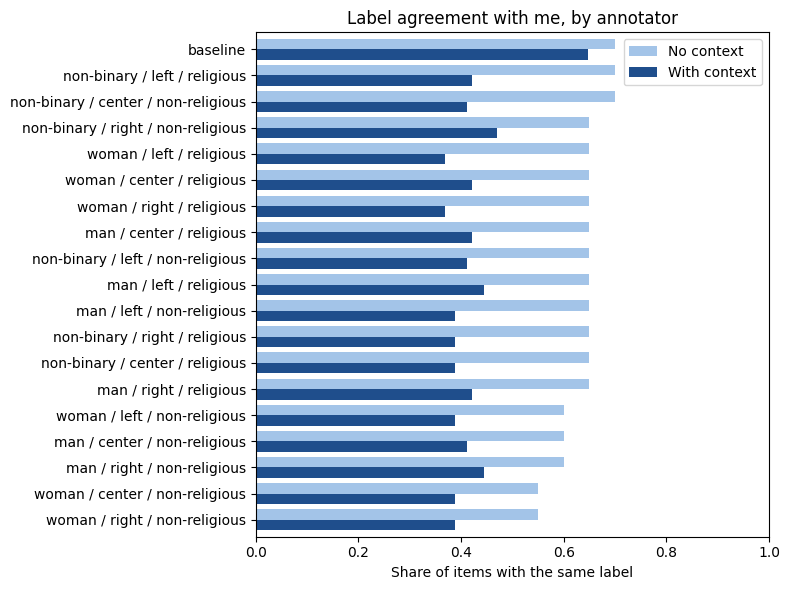

In [23]:
# comparisons 1 and 2: you against each annotator
vs_you = pd.DataFrame({
    "label_E": {a: agree(me, E[a], True) for a in annotators},
    "label_D": {a: agree(me, D[a], True) for a in annotators},
    "exact_E": {a: agree(me, E[a]) for a in annotators},
    "exact_D": {a: agree(me, D[a]) for a in annotators},
}).sort_values("label_E", ascending=False)
display(vs_you.round(2))

print("Closest without context:", vs_you["label_E"].idxmax())
print("Closest with context:", vs_you["label_D"].idxmax())
print("Baseline:", vs_you.loc["baseline"].round(2).to_dict())

plot = vs_you[["label_E", "label_D"]].rename(columns={"label_E": "No context", "label_D": "With context"})
ax = plot.plot.barh(figsize=(8, 6), color=["#a3c4e8", "#1f4e8c"], width=0.8)
ax.set(title="Label agreement with me, by annotator", xlabel="Share of items with the same label", ylabel="", xlim=(0, 1))
ax.invert_yaxis()
plt.tight_layout()
plt.show()


### Comparison 3: how much the context moves each annotator

`mean_change` is the average of (rating with context − rating without context). It is **negative for all 19 annotators**: every annotator rates the items as less toxic after reading the conversation, by 0.2 to 0.8 points on average.

- **Personas move steadily towards "civil"** (−0.33 to −0.83). The non-binary personas move most (−0.63 to −0.83), and *woman / center / non-religious* and the two right-wing non-religious personas least (−0.33 to −0.39).
- **The baseline has the smallest average shift (−0.18) but the lowest exact stability (41% of ratings unchanged).** It changes many ratings in both directions, which largely cancel out, whereas the personas shift consistently downwards. This is why the baseline stays close to me with context and the personas do not.
- **A likely reason:** most generated conversations are calm and reasonable, even about hostile comments, so after reading them the model judges the item as milder. The conversation, not the item, sets the tone.

***Note that:*** Points aren't labels. A drop from 4 to 3 changes the rating but not the label, which stays toxic. A drop from 3 to 2 flips toxic to civil. So `mean_change` measures how far the ratings shift, while `label_same` shows how many items actually changed label.

In [24]:
# comparison 3: how far the context moves each annotator
moved = pd.DataFrame({
    "label_same": {a: agree(E[a], D[a], True) for a in annotators},
    "exact_same": {a: agree(E[a], D[a]) for a in annotators},
    "mean_change": {a: (D[a] - E[a]).mean() for a in annotators},   # above 0: more toxic with context
}).sort_values("exact_same")
display(moved.round(2))


,label_same,exact_same,mean_change
baseline,0.59,0.41,-0.18
non-binary / center / non-religious,0.59,0.41,-0.76
non-binary / left / religious,0.58,0.47,-0.63
man / left / religious,0.61,0.50,-0.44
man / center / religious,0.63,0.53,-0.37
woman / center / religious,0.63,0.53,-0.37
man / right / religious,0.63,0.53,-0.47
non-binary / left / non-religious,0.65,0.53,-0.82
non-binary / right / non-religious,0.71,0.53,-0.65
man / left / non-religious,0.67,0.56,-0.67


### Comparison 4: annotator against annotator

**What the heatmaps show.** Each cell is the label agreement between two annotators: the share of items on which both say civil or both say toxic. Darker means more agreement. The diagonal is always 1, because an annotator always agrees with itself. The first row and column are the baseline. The title gives the mean over all pairs.

| | Mean label agreement | Mean exact agreement |
|---|---|---|
| No context | 0.94 | 0.85 |
| With context | 0.97 | 0.96 |

**The personas are almost interchangeable.** Without context they agree on 94% of labels, and with context on 97%, with exact ratings rising from 85% to 96%. Identity changes the model's ratings very little, and **after reading the conversation the personas agree even more**: the context removes what small differences identity made. In the D heatmap, the baseline's row stands out as lighter, because the baseline is the one annotator that does not follow the personas' shift towards civil.


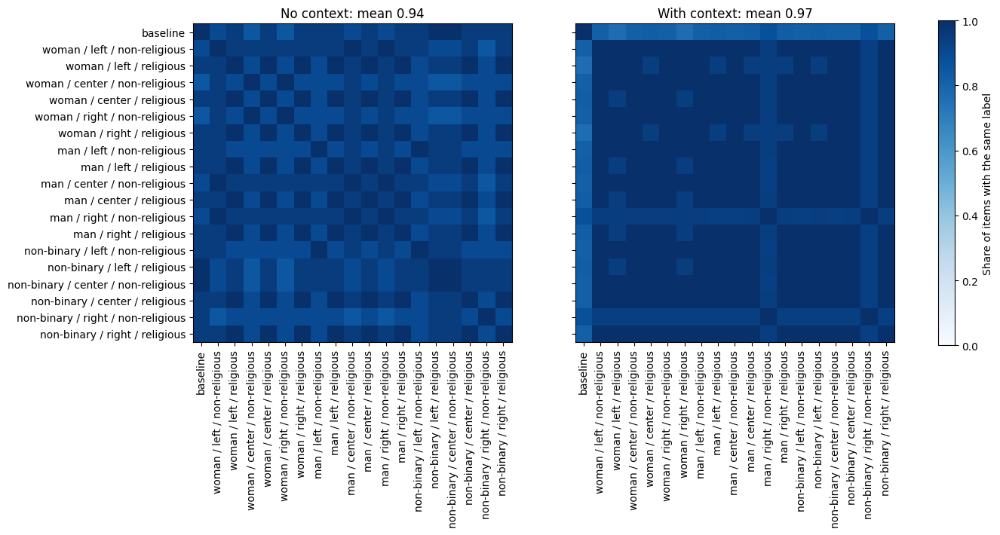

No context | mean label: 0.939 | mean exact: 0.847
With context | mean label: 0.967 | mean exact: 0.96


In [25]:
# comparison 4: annotator against annotator
def pair_table(ratings, categorical):
    names = list(annotators)
    return pd.DataFrame([[agree(ratings[a], ratings[b], categorical) for b in names] for a in names],
                        index=names, columns=names)

def mean_off_diagonal(table):
    return table.values[~np.eye(len(table), dtype=bool)].mean()

tables = {"No context": pair_table(E, True), "With context": pair_table(D, True)}

fig, axes = plt.subplots(1, 2, figsize=(15, 7), sharey=True)
for ax, (title, table) in zip(axes, tables.items()):
    image = ax.imshow(table, cmap="Blues", vmin=0, vmax=1)
    ax.set_title(f"{title}: mean {mean_off_diagonal(table):.2f}")
    ax.set_xticks(range(len(table)), table.columns, rotation=90)
    ax.set_yticks(range(len(table)), table.index)
fig.colorbar(image, ax=axes, label="Share of items with the same label", shrink=0.8)
plt.show()

for title, ratings in [("No context", E), ("With context", D)]:
    print(title, "| mean label:", round(mean_off_diagonal(pair_table(ratings, True)), 3),
          "| mean exact:", round(mean_off_diagonal(pair_table(ratings, False)), 3))


**Which dimension matters most.** I compare personas that differ in only one dimension. Lower agreement would mean that dimension separates them more.

| Dimension | No context (label / exact) | With context (label / exact) |
|---|---|---|
| Religion | 0.93 / 0.88 | 0.99 / 0.98 |
| Gender | 0.96 / 0.87 | 0.98 / 0.98 |
| Politics | 0.97 / 0.91 | 0.98 / 0.98 |

**No dimension clearly separates the personas.** Even the lowest value, 0.93 for **religion** without context, means two personas that differ only in religion disagree on about one item in 20 on average. The differences between dimensions are smaller than one item. They are not even consistent: religion has the lowest label agreement, but gender has the lowest exact agreement. With 20 items, these gaps are within noise. With context, all three are about 0.98. For this model, the persona's gender, politics and religion make almost no difference to its ratings. What changes the ratings is the context it reads.


In [26]:
# which dimension separates personas most: pairs that differ in only that dimension
rows = []
personas = [a for a in annotators if a != "baseline"]
for title, ratings in [("No context", E), ("With context", D)]:
    for a, b in itertools.combinations(personas, 2):
        diff = [d for d in DIMENSIONS if annotators[a][d] != annotators[b][d]]
        if len(diff) == 1:
            rows.append({"condition": title, "dimension": diff[0],
                         "label": agree(ratings[a], ratings[b], True), "exact": agree(ratings[a], ratings[b])})

display(pd.DataFrame(rows).groupby(["condition", "dimension"])[["label", "exact"]].mean().round(2))


label  exact
condition    dimension              
No context   gender      0.96   0.87
             politics    0.97   0.91
             religion    0.93   0.88
With context gender      0.98   0.98
             politics    0.98   0.98
             religion    0.99   0.98

## G. Conclusions

1. **Personas barely matter for this model.** Personas agree with each other on 94% of labels without context, and no dimension (gender, politics or religion) clearly separates them: pairs differing in one dimension disagree on about one item in 20 at most. I added religion because several of my items are about religion and ethnicity, but the expectation that it would matter was not confirmed.
2. **The conversation changes the labels, and in one direction.** Every annotator rates less toxic after reading it, by 0.2 to 0.8 points on average on the 1–5 scale, and uses a narrower part of the scale. The personas also become even more alike (97% label agreement): the context outweighs identity.
3. **Context brings the persona annotators further from me.** Their label agreement with me falls from 55–70% (around the 60% of always answering "toxic") to 37–47% (around the 40% of always answering "civil"). The baseline drops only from 70% to 65%.
4. **The closest annotator to me is the baseline,** not any persona. The closest persona, *non-binary / center / non-religious*, is closest only without context, by a margin of about one item.
5. **I rated more harshly than the model.** I labelled 12 of 20 items toxic. Even where we agree on the label, we rarely agree on the exact level (11–35% exact agreement).

**Limitations.**
- **Only 20 items:** one item moves any agreement value by about 5 points, so only differences of several items mean much.
- **A small model:** a 3B model largely ignores personas, partly breaks the output format, and wrote conversations with repetition and misreadings (see the model section).
- **One generated conversation per item:** the context effect is the effect of *these* conversations, which I shaped through the pool, stances and instructions. They are themselves a source of bias, and the same model both wrote them and read them.
- **Personas are only descriptions:** a short dictionary of attributes is not a person. Agreement with a persona says nothing about how real people with that identity would rate.
- **Simplified instructions:** the model's instructions omit some of the page's guidance that I followed (tone versus topic, swear words, quoted words).
